# APS Battery Feasibility Lab: measured demand review

**Independent Arizona storage research · October 10, 2026**

## tl;dr
Three measured AZPS summers show that dispatch timing can matter more than extra battery energy in this daily demand-only screen. For a 100 MW four-hour system, prior-week dispatch reduces the period-peak proxy by **99.5 MW (2024), -0.5 MW (2025), and 34.5 MW (2026)**. Hindsight reaches 99.5 MW in each summer. Six/eight hours do not improve these period-peak results.

**Decision:** use four hours as a reference for further diligence. Longer duration needs evidence of additional buyer value, future net-load needs or reliability contribution. These modeled reductions are not measured APS savings, ELCC or project approval. Capital costs are illustrative.

This notebook contains saved outputs and reruns a measured case in a temporary directory. Setup: Python 3.12 and `python -m pip install -r requirements-reproducible.txt` from the repository root.

## Context & Methods

The question is whether longer duration merits further work for an APS-oriented development case. Public APS procurement documents motivate 4/6/8-hour comparisons. A daily MILP minimizes a load-envelope proxy with exclusive charging/discharging, power limits, energy limits and a terminal energy balance.

### Key Assumptions
- 100 MW modeled AC battery output before 0.5 MW auxiliary demand; 400/600/800 usable AC MWh.
- Base round-trip efficiency 88%, illustrative. A separate 2025 ATB-inspired case uses 85%, 15-year life and 4%-of-capex fixed O&M including augmentation.
- Each day begins and ends at 50% SOC. Daily reset excludes rolling multi-day adequacy.
- Prior-week forecast uses exactly the same hours seven days earlier. Hindsight knows actual demand and is a comparator.
- Revised EIA history does not establish the historical as-of information set. Availability is assumed known and is 100% in the measured base.
- The developer fee model is separate from dispatch value. It includes no utility savings, debt, taxes or achievable contract-price evidence.

Sources and scope: [source register](../SOURCES.md), [research update](../RESEARCH_UPDATE.md), [full guide](../PROJECT_GUIDE.md).

In [1]:
from pathlib import Path
import sys, json, tempfile
from hashlib import sha256
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "lab.py").exists():
    ROOT = ROOT.parent
assert (ROOT / "lab.py").exists(), "Run from the repository root or notebooks folder"
sys.path.insert(0, str(ROOT))
from lab import run, validate_frame
from verify_results import audit_results
plt.rcParams.update({"figure.figsize": (10, 5), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelcolor": "#193446", "text.color": "#193446"})
FIGURES = ROOT / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

def finish(fig, filename):
    fig.tight_layout()
    fig.savefig(FIGURES / filename, dpi=160, bbox_inches="tight")
    display(Image(filename=str(FIGURES / filename)))
    plt.close(fig)

YEARS = [2024, 2025, 2026]
base = json.loads((ROOT / "config.json").read_text())
measured = ROOT / "results" / "measured"
summary = pd.concat([pd.read_csv(measured / str(y) / "dispatch_summary.csv").assign(year=y)
                     for y in YEARS], ignore_index=True)
print("Loaded three measured summers; source data and assumptions remain separate.")

Loaded three measured summers; source data and assumptions remain separate.


## Data

Each input covers May 25–September 30. The first seven days are forecast warmup; evaluation is June 1–September 30, **122 days per summer**. The consistent source column is EIA **Adjusted demand**. No local gap filling was performed.

EIA adjusted one May 2026 warmup hour from reported 20,345 MW to 2,309 MW. The raw reported-value experiment is retained. This prevents a flagged source value from silently entering the main forecast. Timestamps are shifted from hour-ending to hour-start UTC and grouped in Phoenix time.

In [2]:
quality = []
for year in YEARS:
    path = ROOT / "data" / "public" / f"azps_summer_{year}.csv"
    meta = json.loads(path.with_suffix(".provenance.json").read_text())
    assert sha256(path.read_bytes()).hexdigest() == meta["canonical_csv_sha256"]
    frame = validate_frame(pd.read_csv(path))
    assert len(frame) == 3096
    quality.append({"Summer": year, "Input hours": len(frame), "Evaluation days": 122,
                    "Local fills": meta["quality"]["filled_rows"],
                    "EIA adjusted hours": meta["quality"]["reported_vs_adjusted_differences"]})
display(pd.DataFrame(quality).set_index("Summer"))
raw = pd.read_csv(measured / "2026_reported_raw" / "dispatch_summary.csv")
clean = summary[(summary.year == 2026) & (summary.duration_hours == 4)
                & (summary.strategy == "lag7_dispatch")].iloc[0]
print(f"2026 forecast MAE: reported-value sensitivity {raw.forecast_mae_mw.iloc[0]:.2f} MW; "
      f"EIA-adjusted main case {clean.forecast_mae_mw:.2f} MW.")

2026 forecast MAE: reported-value sensitivity 747.07 MW; EIA-adjusted main case 742.09 MW.


,Input hours,Evaluation days,Local fills,EIA adjusted hours
Summer,,,,
2024,3096,122,0,0
2025,3096,122,0,0
2026,3096,122,0,1


## Results

### 1. Compare the same metric across summers
The period-peak metric compares maxima over the same evaluated hours, including charging. Negative values remain visible. Each year is a separate weather/load realization; these three values are not a confidence interval.

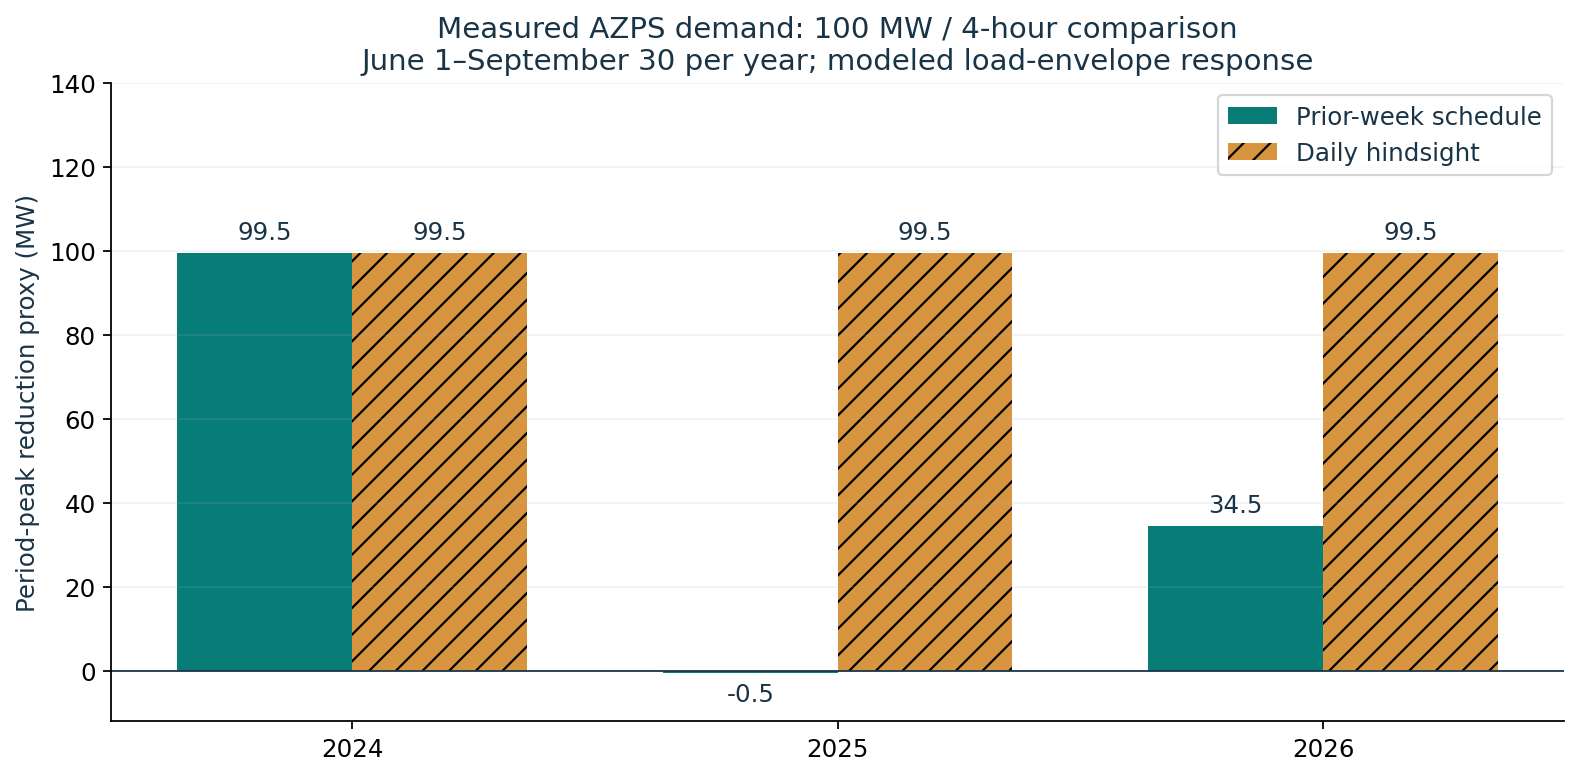

,Summer,strategy,baseline_period_peak_mw,period_peak_reduction_proxy_mw,mean_daily_peak_reduction_proxy_mw
0,2024,lag7_dispatch,8207.0,99.5,54.88
1,2024,hindsight_daily_bound,8207.0,99.5,99.50
2,2025,lag7_dispatch,8499.0,-0.5,38.69
3,2025,hindsight_daily_bound,8499.0,99.5,99.50
4,2026,lag7_dispatch,8982.0,34.5,33.32
5,2026,hindsight_daily_bound,8982.0,99.5,99.50


In [3]:
four = summary[summary.duration_hours == 4]
peak = four.pivot(index="year", columns="strategy", values="period_peak_reduction_proxy_mw")
fig, ax = plt.subplots()
x = np.arange(len(YEARS))
for offset, strategy, label, color, hatch in [(-.18, "lag7_dispatch", "Prior-week schedule", "#087d78", ""),
                                            (.18, "hindsight_daily_bound", "Daily hindsight", "#d89540", "//")]:
    values = peak[strategy].to_numpy()
    bars = ax.bar(x + offset, values, width=.36, label=label, color=color, hatch=hatch)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], padding=4)
ax.axhline(0, color="#193446", lw=.8)
ax.set_xticks(x, YEARS); ax.set_ylim(-12, 140)
ax.set_ylabel("Period-peak reduction proxy (MW)")
ax.set_title("Measured AZPS demand: 100 MW / 4-hour comparison\nJune 1–September 30 per year; modeled load-envelope response")
ax.legend(loc="upper right"); ax.grid(axis="y", alpha=.15)
finish(fig, "measured_peak_comparison.png")
display(four[["year", "strategy", "baseline_period_peak_mw",
              "period_peak_reduction_proxy_mw", "mean_daily_peak_reduction_proxy_mw"]]
        .rename(columns={"year": "Summer"}).round(2).reset_index(drop=True))

The four-hour hindsight result reaches the modeled 99.5 MW net-power limit in every summer. The prior-week schedule can miss the critical hour, as in 2025. These are model calculations on measured demand, not changes observed after a real battery was installed.

### 2. Does more energy improve realized daily support?
This chart uses the mean of 122 daily peak reductions per summer. It answers a different question from the period-peak metric. A schedule optimized on a stale forecast can get worse when additional energy changes its timing.

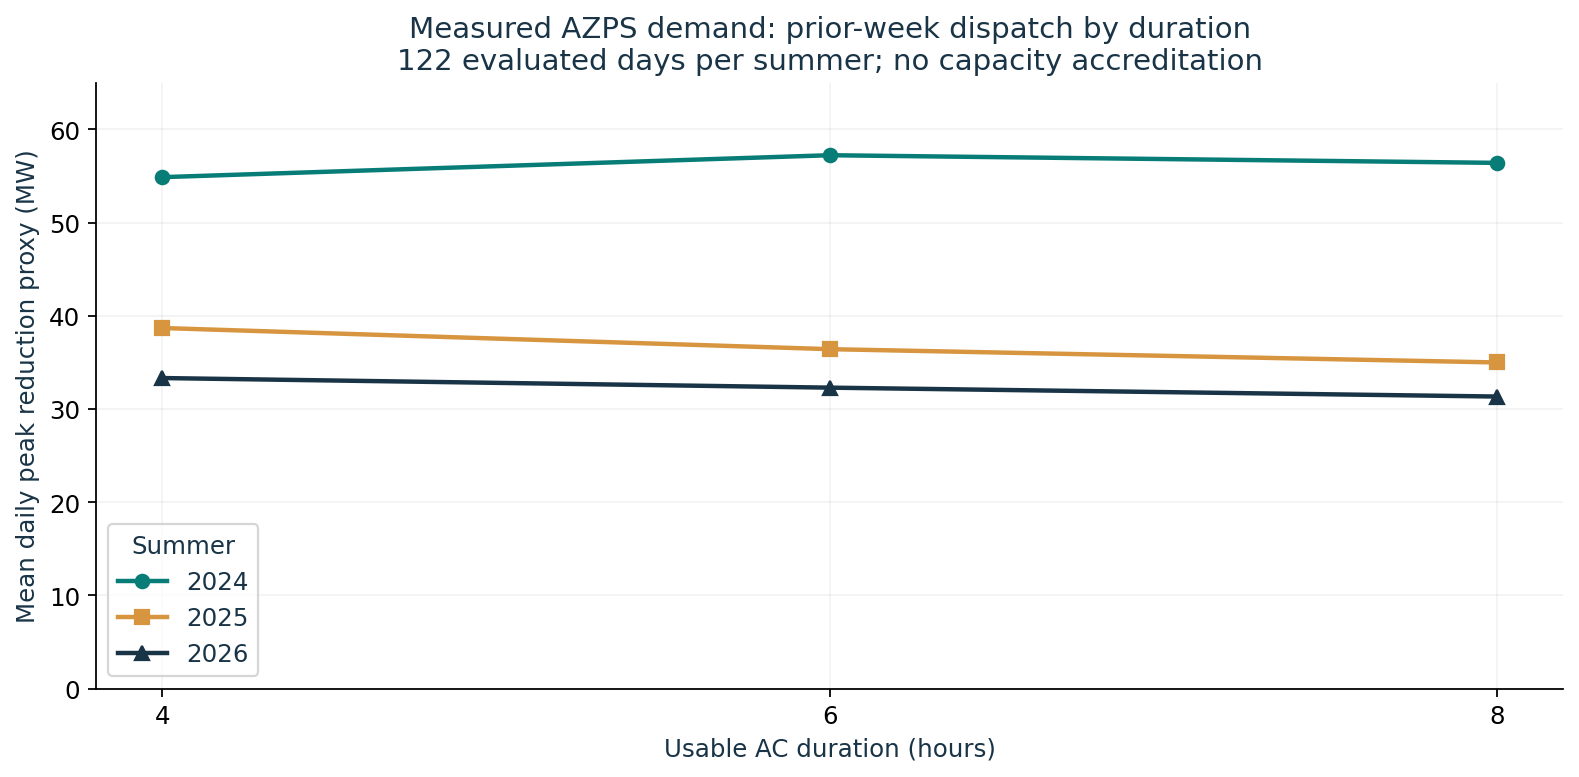

In [4]:
fig, ax = plt.subplots()
for year, color, marker in [(2024, "#087d78", "o"), (2025, "#d89540", "s"), (2026, "#193446", "^")]:
    s = summary[(summary.year == year) & (summary.strategy == "lag7_dispatch")]
    ax.plot(s.duration_hours, s.mean_daily_peak_reduction_proxy_mw, marker=marker,
            color=color, lw=2, label=str(year))
ax.set_xticks([4, 6, 8]); ax.set_ylim(0, 65)
ax.set_xlabel("Usable AC duration (hours)"); ax.set_ylabel("Mean daily peak reduction proxy (MW)")
ax.set_title("Measured AZPS demand: prior-week dispatch by duration\n122 evaluated days per summer; no capacity accreditation")
ax.legend(title="Summer"); ax.grid(alpha=.15)
finish(fig, "measured_daily_duration.png")

### 3. Inspect the 2025 peak-day failure
The day is selected from the measured 2025 evaluation data, not chosen for an attractive dispatch result. Inspect the actual demand, forecast, adjusted proxy and battery energy together.

Peak-day prior-week discharge at actual maximum demand: 0.0 MW


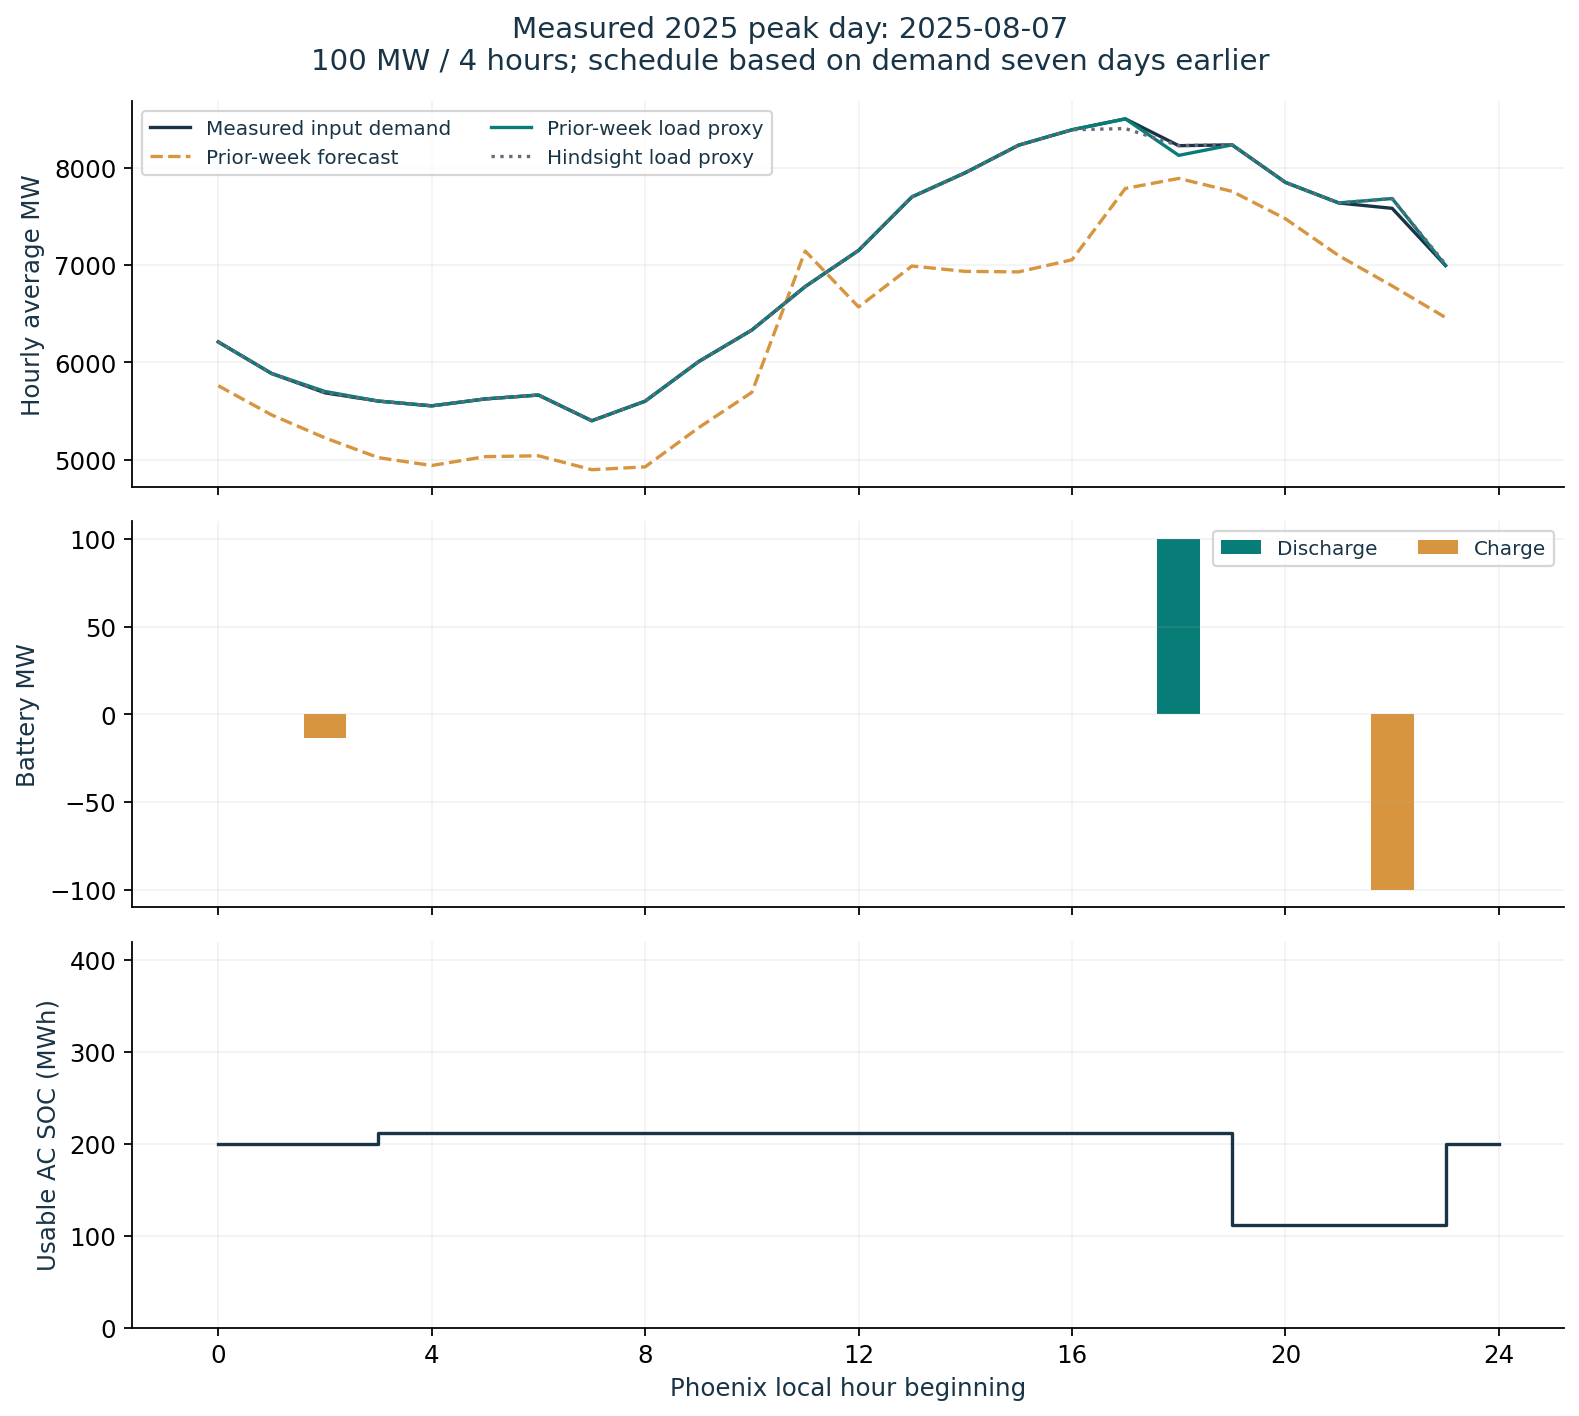

In [5]:
hourly = pd.read_csv(measured / "2025" / "hourly_dispatch.csv.gz")
lag = hourly[(hourly.duration_hours == 4) & (hourly.strategy == "lag7_dispatch")]
peak_day = lag.loc[lag.load_mw.idxmax(), "local_date"]
day = lag[lag.local_date == peak_day]
hindsight = hourly[(hourly.duration_hours == 4) & (hourly.strategy == "hindsight_daily_bound")
                   & (hourly.local_date == peak_day)]
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
axes[0].plot(day.hour_local, day.load_mw, color="#193446", label="Measured input demand")
axes[0].plot(day.hour_local, day.forecast_mw, color="#d89540", ls="--", label="Prior-week forecast")
axes[0].plot(day.hour_local, day.adjusted_load_proxy_mw, color="#087d78", label="Prior-week load proxy")
axes[0].plot(hindsight.hour_local, hindsight.adjusted_load_proxy_mw, color="#6c6879", ls=":", label="Hindsight load proxy")
axes[0].set_ylabel("Hourly average MW"); axes[0].legend(fontsize=9, ncol=2)
axes[1].bar(day.hour_local, day.discharge_mw, color="#087d78", label="Discharge")
axes[1].bar(day.hour_local, -day.charge_mw, color="#d89540", label="Charge")
axes[1].set_ylabel("Battery MW"); axes[1].legend(ncol=2, fontsize=9)
soc = np.r_[day.soc_start_mwh.iloc[0], day.soc_end_mwh.to_numpy()]
axes[2].step(np.arange(25), soc, where="post", color="#193446")
axes[2].set_ylim(0, 420); axes[2].set_ylabel("Usable AC SOC (MWh)")
axes[2].set_xlabel("Phoenix local hour beginning")
axes[2].set_xticks([0, 4, 8, 12, 16, 20, 24])
for ax in axes: ax.grid(alpha=.15)
fig.suptitle(f"Measured 2025 peak day: {peak_day}\n100 MW / 4 hours; schedule based on demand seven days earlier")
finish(fig, "measured_peak_day_failure.png")
print("Peak-day prior-week discharge at actual maximum demand:",
      round(float(day.loc[day.load_mw.idxmax(), "discharge_mw"]), 2), "MW")

### 4. Quantify the contract-cost burden
The fee covers illustrative capex, fixed O&M and augmentation at a stated real discount rate. A higher fee requirement does not show that a buyer will pay it. The 2025 ATB-inspired case changes efficiency, life and O&M together; it is not a single-variable attribution or an ATB capital-price quote.

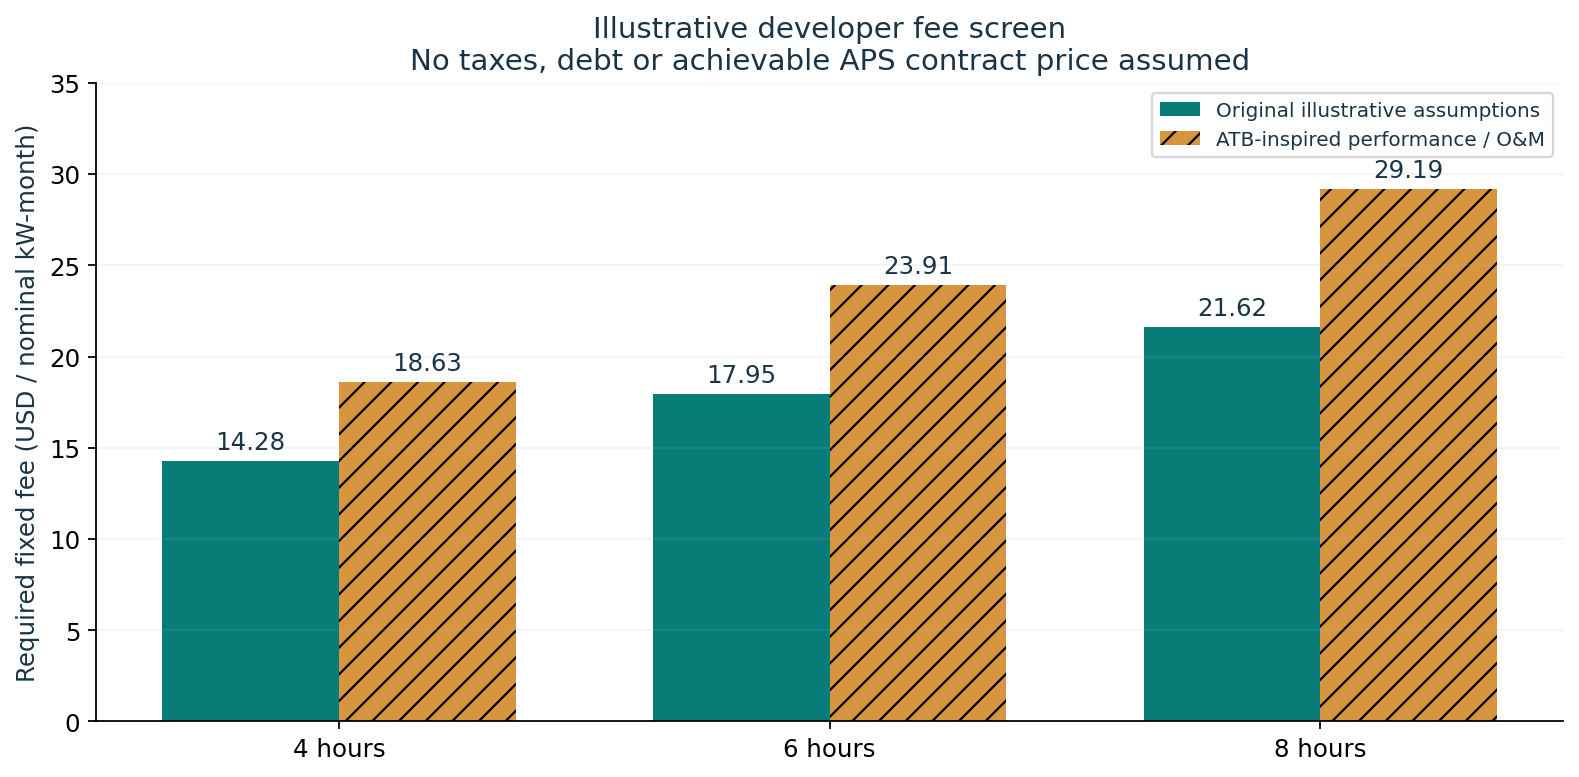

,Duration (hours),Original fee (USD/kW-month),Benchmark fee (USD/kW-month)
0,4,14.28,18.63
1,6,17.95,23.91
2,8,21.62,29.19


In [6]:
fee_base = pd.read_csv(measured / "2026" / "finance_screen.csv")
fee_benchmark = pd.read_csv(measured / "2026_atb_performance" / "finance_screen.csv")
fig, ax = plt.subplots()
x = np.arange(3)
for offset, frame, label, color, hatch in [(-.18, fee_base, "Original illustrative assumptions", "#087d78", ""),
                                         (.18, fee_benchmark, "ATB-inspired performance / O&M", "#d89540", "//")]:
    bars = ax.bar(x + offset, frame.required_fixed_fee_usd_per_kw_month, .36,
                  label=label, color=color, hatch=hatch)
    ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set_xticks(x, ["4 hours", "6 hours", "8 hours"]); ax.set_ylim(0, 35)
ax.set_ylabel("Required fixed fee (USD / nominal kW-month)")
ax.set_title("Illustrative developer fee screen\nNo taxes, debt or achievable APS contract price assumed")
ax.legend(fontsize=9); ax.grid(axis="y", alpha=.15)
finish(fig, "financial_benchmark.png")
fee_table = pd.DataFrame({"Duration (hours)": [4, 6, 8],
                         "Original fee (USD/kW-month)": fee_base.required_fixed_fee_usd_per_kw_month,
                         "Benchmark fee (USD/kW-month)": fee_benchmark.required_fixed_fee_usd_per_kw_month})
display(fee_table.round(2))

### 5. Test interconnection and energy-cost assumptions
This is a deterministic scenario grid, not a statistical confidence interval. The three upgrade allowances and energy-cost multipliers are analyst assumptions. Real upgrade estimates require system studies.

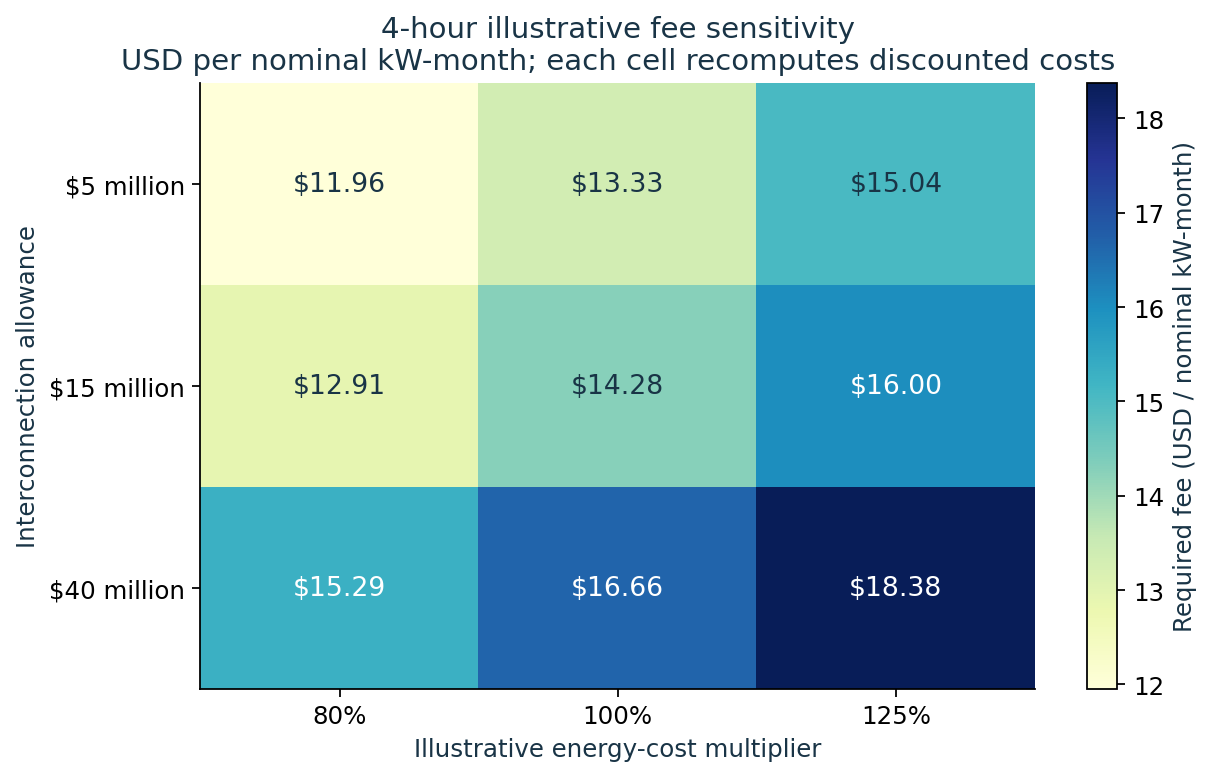

In [7]:
cost = pd.read_csv(measured / "2026" / "cost_sensitivity.csv")
grid = cost[cost.duration_hours == 4].pivot(index="upgrade_cost_usd", columns="energy_cost_multiplier",
                                          values="required_fixed_fee_usd_per_kw_month")
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(grid.to_numpy(), cmap="YlGnBu", aspect="auto")
ax.set_xticks(range(3), ["80%", "100%", "125%"])
ax.set_yticks(range(3), ["$5 million", "$15 million", "$40 million"])
ax.set_xlabel("Illustrative energy-cost multiplier"); ax.set_ylabel("Interconnection allowance")
ax.set_title("4-hour illustrative fee sensitivity\nUSD per nominal kW-month; each cell recomputes discounted costs")
mid = (grid.to_numpy().min() + grid.to_numpy().max()) / 2
for i in range(3):
    for j in range(3):
        v = grid.iloc[i, j]
        ax.text(j, i, f"${v:.2f}", ha="center", va="center", fontsize=12,
                color="white" if v > mid else "#193446")
fig.colorbar(im, ax=ax, label="Required fee (USD / nominal kW-month)")
finish(fig, "interconnection_sensitivity.png")

## Checks
Audit all six measured cases, then independently rerun 2026 from the canonical input in a temporary directory. Compare the entire numerical summary with the published outputs. The optional authenticated API adapter is mock-tested; the key-free public workbook route was actually downloaded and inspected for this release.

In [8]:
cases = ["2024", "2025", "2026", "2026_reported_raw", "2026_derated", "2026_atb_performance"]
display(pd.DataFrame([dict(Case=name, **audit_results(measured / name)) for name in cases]))
p = ROOT / "data" / "public" / "azps_summer_2026.csv"
with tempfile.TemporaryDirectory(prefix="aps-review-") as temp:
    run(pd.read_csv(p), base, temp, {"data_mode": "measured-eia-demand", "source_label": "Included EIA adjusted 2026 snapshot",
                                   "input_sha256": sha256(p.read_bytes()).hexdigest()})
    check = audit_results(temp)
    actual = pd.read_csv(Path(temp) / "dispatch_summary.csv")
    expected = pd.read_csv(measured / "2026" / "dispatch_summary.csv")
    pd.testing.assert_frame_equal(actual, expected, check_exact=False, atol=1e-4, rtol=1e-7)
print("PASS: rerun summary matches all numerical and categorical fields; physics and fee audit passed.")

 duration_hours              strategy  period_peak_reduction_proxy_mw
              4         lag7_dispatch                            34.5
              4 hindsight_daily_bound                            99.5
              6         lag7_dispatch                            34.5
              6 hindsight_daily_bound                            99.5
              8         lag7_dispatch                            34.5
              8 hindsight_daily_bound                            99.5
Outputs: /tmp/aps-review-ok89wp4f | measured-eia-demand
PASS: rerun summary matches all numerical and categorical fields; physics and fee audit passed.


,Case,data_mode,comparisons,hourly_records,evaluated_days,physics_and_finance
0,2024,measured-eia-demand,6,17568,122,passed
1,2025,measured-eia-demand,6,17568,122,passed
2,2026,measured-eia-demand,6,17568,122,passed
3,2026_reported_raw,measured-eia-demand,6,17568,122,passed
4,2026_derated,measured-eia-demand,6,17568,122,passed
5,2026_atb_performance,measured-eia-demand,6,17568,122,passed


## Takeaways

1. **Start with four hours for further diligence.** In this measured demand-only experiment, six/eight hours do not improve the summer-period peak metric, while illustrative cost requirements increase.
2. **Validate timing before adding energy.** A prior-week forecast misses the highest 2025 demand hour. Hindsight identifies what the same physical battery could do with perfect daily demand knowledge.
3. **Separate measured data, simulated response and commercial assumptions.** The load is measured; dispatch is modeled; project costs and fees are illustrative.
4. **Preserve corrections and failures.** The single EIA-adjusted warmup hour is documented, the raw sensitivity remains available, and negative reductions remain visible.
5. **Use the next evidence to change the decision.** Buyer dispatch requirements, future net load, rolling SOC, ELCC, manufacturer heat curves, site-specific upgrades and quoted contract economics could justify a different duration.

The study covers summer demand, not annual reliability or overnight year-round needs. Historical revised observations and assumed availability do not establish a historical as-of replay. No site, procurement award or investment feasibility is certified.

Detailed references and development requirements are in `RESEARCH_UPDATE.md` and `SOURCES.md`. The project was prepared with AI assistance; understand and reproduce it before discussing it in an application.